In [1]:
%load_ext autoreload
%autoreload 2

# Task 4.7 - Capacity Assessment

We estimate the probability that the daily cargo throughput exceeds the operational capacity of
650,000 tons/day, both today and over the next decade, and how much a new terminal with a capacity
of 800,000 tons/day would help.

All simulations use the seasonal compound Poisson model: monthly arrival rates per vessel type, and a
lognormal cargo distribution per vessel type, all estimated with the method of moments.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from toolkit import load_data, moments, fit_lognormal, simDailyCPP
np.random.seed(42)

In [3]:
df = load_data()
d = df['Arrival_Date']

vessel_types = ["Container", "Tanker", "Bulk"]
month_lengths = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

days_per_month = d.dt.normalize().drop_duplicates().dt.month.value_counts().sort_index()
monthly_rates = (
    df.groupby(['Arrival_Month', 'Vessel_Type'], observed=True)
      .size()
      .unstack()
      .div(days_per_month, axis=0)
)[vessel_types]

moments_for_types = [moments(df[df['Vessel_Type'] == t]['Cargo_tons']) for t in vessel_types]
dists = tuple(fit_lognormal(mom) for mom in moments_for_types)

capacity = 650000
new_capacity = 800000

## Growth over the next decade

The dataset covers only three years and shows no trend between them, so the growth rate cannot be
estimated from the data. Instead we look at a range of annual growth rates $g$ of 1%, 2% and 3%.
Growth is modelled as more vessel arrivals, with the cargo per vessel unchanged. After $y$ years
the arrival rate of vessel type $v$ in month $m$ is

$$\lambda_{v,m}(y) = (1 + g)^y \, \lambda_{v,m}$$

Year $y = 0$ is the current situation. For every combination of growth rate and year we simulate
the daily throughput over many years and record how often it exceeds the current capacity and
the capacity with the new terminal.

In [4]:
growth_rates = [0.01, 0.02, 0.03]
years = range(0, 11)
nsim = 60

rows = []

for g in growth_rates:
    for y in years:
        factor = (1 + g) ** y
        grown_lambdas = [tuple(factor * monthly_rates.loc[m, vessel_types]) for m in range(1, 13)]

        S = np.zeros((nsim, 365))
        for i in range(nsim):
            S[i] = simDailyCPP(grown_lambdas, dists, month_lengths)[:, 7]

        rows.append({
            'Growth': g,
            'Year': y,
            'Factor': factor,
            'P(S > 650k)': np.mean(S > capacity),
            'P(S > 800k)': np.mean(S > new_capacity),
        })

growth_df = pd.DataFrame(rows)
growth_df['Days > 650k per year'] = growth_df['P(S > 650k)'] * 365
growth_df['Days > 800k per year'] = growth_df['P(S > 800k)'] * 365
growth_df.round(4)

,Growth,Year,Factor,P(S > 650k),P(S > 800k),Days > 650k per year,Days > 800k per year
0,0.01,0,1.0000,0.0326,0.0033,11.9167,1.2000
1,0.01,1,1.0100,0.0357,0.0026,13.0333,0.9333
2,0.01,2,1.0201,0.0390,0.0044,14.2500,1.6167
3,0.01,3,1.0303,0.0407,0.0038,14.8667,1.3833
4,0.01,4,1.0406,0.0421,0.0053,15.3833,1.9167
5,0.01,5,1.0510,0.0460,0.0050,16.8000,1.8167
6,0.01,6,1.0615,0.0487,0.0050,17.7833,1.8333
7,0.01,7,1.0721,0.0546,0.0061,19.9167,2.2333
8,0.01,8,1.0829,0.0546,0.0061,19.9333,2.2333
9,0.01,9,1.0937,0.0602,0.0074,21.9833,2.7000


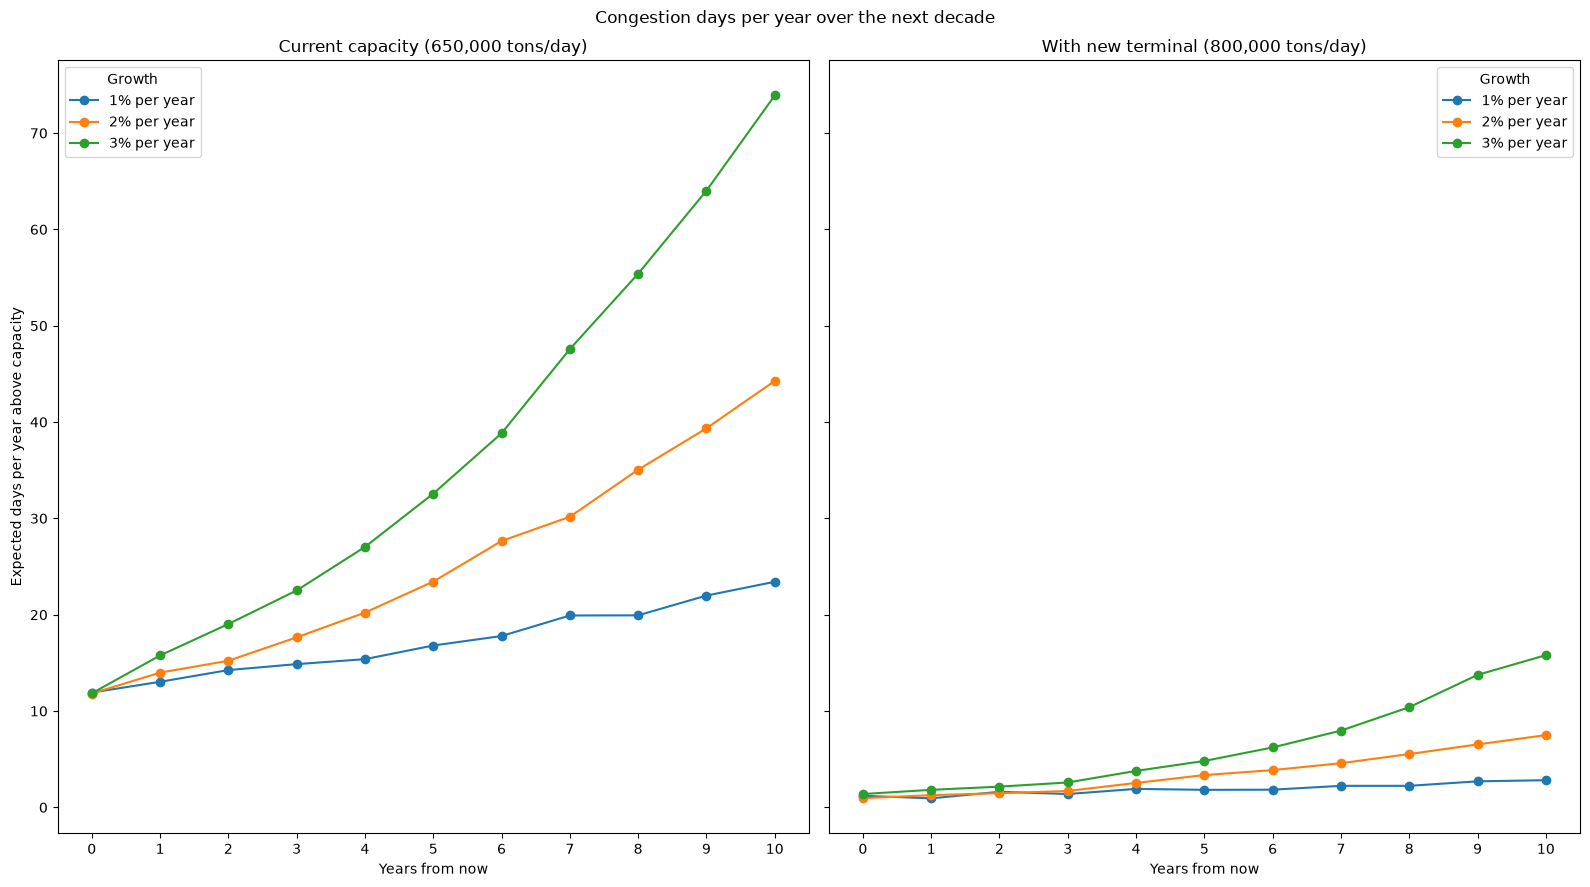

In [5]:
fig, ax = plt.subplots(figsize = (16, 9), ncols=2, sharey=True)

for g in growth_rates:
    rows_g = growth_df[growth_df['Growth'] == g]
    ax[0].plot(rows_g['Year'], rows_g['Days > 650k per year'], marker='o', label=f"{g:.0%} per year")
    ax[1].plot(rows_g['Year'], rows_g['Days > 800k per year'], marker='o', label=f"{g:.0%} per year")

ax[0].set_title("Current capacity (650,000 tons/day)")
ax[1].set_title("With new terminal (800,000 tons/day)")
for a in ax:
    a.set_xlabel("Years from now")
    a.set_xticks(list(years))
    a.legend(title="Growth")
ax[0].set_ylabel("Expected days per year above capacity")
fig.suptitle("Congestion days per year over the next decade")
plt.tight_layout()

In [6]:
decade_df = (
    growth_df[growth_df['Year'] == 10]
      .set_index('Growth')
      [['Factor', 'P(S > 650k)', 'Days > 650k per year', 'P(S > 800k)', 'Days > 800k per year']]
)
decade_df.round(4)

,Factor,P(S > 650k),Days > 650k per year,P(S > 800k),Days > 800k per year
Growth,,,,,
0.01,1.1046,0.0642,23.4167,0.0077,2.8167
0.02,1.2190,0.1213,44.2667,0.0205,7.5000
0.03,1.3439,0.2025,73.9000,0.0433,15.8000


### Growth through larger cargo instead of more arrivals

The same growth in throughput could also come from vessels carrying more cargo instead of more
vessels arriving. Both raise the mean throughput by the same factor $F = (1+g)^{10}$, but they
affect the variance differently. In the seasonal model from 4.4, $\text{Var}[S(t)] = \sum_v \Lambda_v(t) \, E[X_v^2]$:
more arrivals multiply $\Lambda_v(t)$, and with it the variance, by $F$, while larger cargo multiplies
$E[X_v^2]$, and with it the variance, by $F^2$. As a sensitivity check we compare both for
$g = 2\%$ after 10 years.

In [7]:
g = 0.02
F = (1 + g) ** 10

larger_dists = tuple(fit_lognormal((F * M1, F**2 * M2)) for M1, M2 in moments_for_types)
base_lambdas = [tuple(monthly_rates.loc[m, vessel_types]) for m in range(1, 13)]

S_cargo = np.zeros((nsim, 365))
for i in range(nsim):
    S_cargo[i] = simDailyCPP(base_lambdas, larger_dists, month_lengths)[:, 7]

arrivals_row = growth_df[(growth_df['Growth'] == g) & (growth_df['Year'] == 10)].iloc[0]
growth_source_df = pd.DataFrame({
    'P(S > 650k)': [arrivals_row['P(S > 650k)'], np.mean(S_cargo > capacity)],
    'P(S > 800k)': [arrivals_row['P(S > 800k)'], np.mean(S_cargo > new_capacity)],
}, index=['More arrivals', 'Larger cargo per vessel'])
growth_source_df['Days > 650k per year'] = growth_source_df['P(S > 650k)'] * 365
growth_source_df['Days > 800k per year'] = growth_source_df['P(S > 800k)'] * 365
growth_source_df.round(4)

,P(S > 650k),P(S > 800k),Days > 650k per year,Days > 800k per year
More arrivals,0.1213,0.0205,44.2667,7.5000
Larger cargo per vessel,0.1365,0.0294,49.8333,10.7333


## Discussion

Will fill out all of these when I start writing the report tbh

### Probability of exceeding capacity


### Operational implications


### Sensitivity to assumptions


### Limitations


### Outlook for the next decade and recommended actions

